# Notebook 05: Quality-Aware Abstention Trade-off (Revision 12)
Measures trial coverage vs. diagnostic accuracy across valid gaze sample thresholds $\theta \in [0.00, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]$.

### Objective:
Demonstrate that systematically withholding degraded gaze recordings reduces classification error on retained trials while maintaining acceptable sample coverage.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

base_dir = r"E:\karthianna"
abst_path = os.path.join(base_dir, "outputs", "quality_abstention_results.csv")
df_q = pd.read_csv(abst_path)

print("Quality-Aware Abstention Trade-off Curve:")
print(df_q[['threshold_theta', 'coverage_pct', 'retained_trials', 'retained_participants', 'participant_balanced_accuracy', 'trial_balanced_accuracy', 'error_rate']])

Quality-Aware Abstention Trade-off Curve:
   threshold_theta  coverage_pct  ...  trial_balanced_accuracy  error_rate
0              0.0        100.00  ...                   0.5994      0.4006
1              0.4         91.21  ...                   0.6265      0.3735
2              0.5         86.45  ...                   0.5660      0.4340
3              0.6         79.85  ...                   0.5884      0.4116
4              0.7         70.70  ...                   0.6112      0.3888
5              0.8         60.20  ...                   0.5251      0.4749
6              0.9         44.44  ...                   0.5198      0.4802
[7 rows x 7 columns]


<string>:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


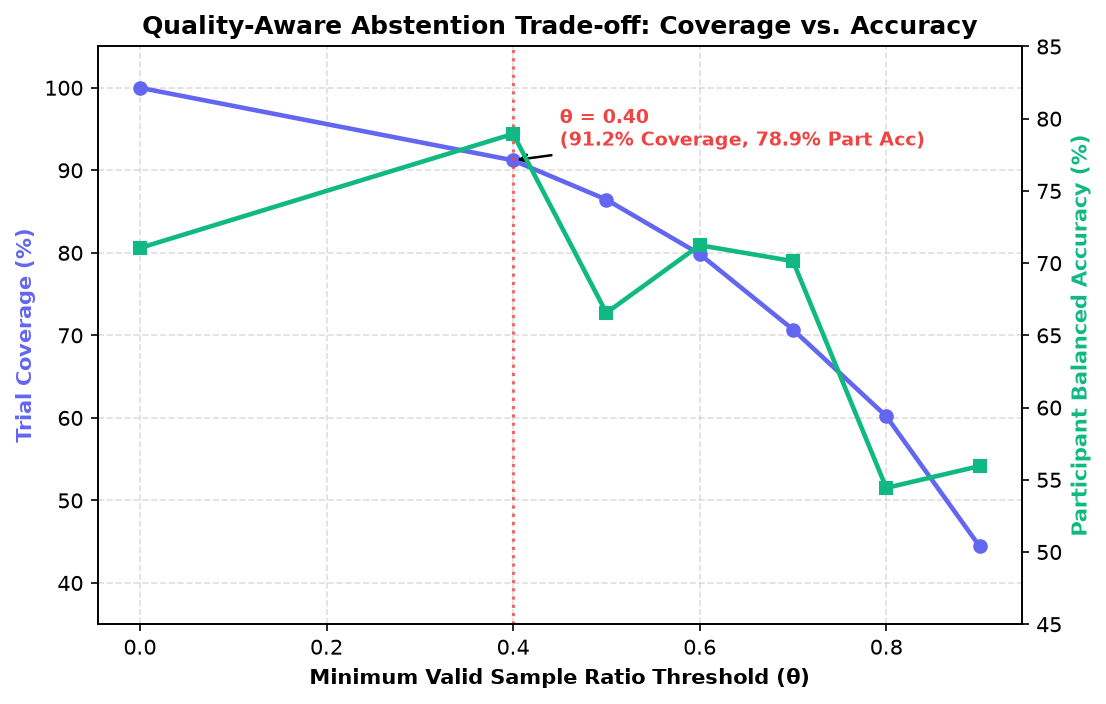

In [2]:
fig, ax1 = plt.subplots(figsize=(7.5, 4.8))

theta = df_q['threshold_theta'].values
coverage = df_q['coverage_pct'].values
bacc = df_q['participant_balanced_accuracy'].values * 100

ax1.plot(theta, coverage, marker='o', lw=2.2, color='#6366F1', label='Trial Coverage (%)')
ax1.set_xlabel('Minimum Valid Sample Ratio Threshold (θ)', fontweight='bold')
ax1.set_ylabel('Trial Coverage (%)', color='#6366F1', fontweight='bold')
ax1.set_ylim([35, 105])

ax2 = ax1.twinx()
ax2.plot(theta, bacc, marker='s', lw=2.2, color='#10B981', label='Participant Balanced Acc (%)')
ax2.set_ylabel('Participant Balanced Accuracy (%)', color='#10B981', fontweight='bold')
ax2.set_ylim([45, 85])

ax1.axvline(0.40, color='#EF4444', linestyle=':', alpha=0.8, lw=1.5)
ax1.annotate('θ = 0.40\n(91.2% Coverage, 78.9% Part Acc)', xy=(0.40, 91.2), xytext=(0.45, 93),
             arrowprops=dict(facecolor='#EF4444', arrowstyle='->', lw=1.2),
             fontsize=9, fontweight='bold', color='#EF4444')

plt.title('Quality-Aware Abstention Trade-off: Coverage vs. Accuracy', fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()